# Implementation of the basic AR model

In [1]:
import glob
import re
import itertools

import matplotlib.pyplot as plt
import scipy.signal
import seaborn as sns
import numpy as np
import pandas as pd

In [2]:
import bidict

In [3]:
import pymc as pm

WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


In [4]:
import arviz as az

In [5]:
import pytensor as pt

In [6]:
from scipy import io

In [7]:
import os

## Data etc

In [8]:
phone_acc_df = pd.read_pickle('data/phone_acc_df.pkl')
phone_gyro_df = pd.read_pickle('data/phone_gyro_df.pkl')
watch_acc_df = pd.read_pickle('data/watch_acc_df.pkl')
watch_gyro_df = pd.read_pickle('data/watch_gyro_df.pkl')

In [9]:
activity_codes = bidict.bidict({
    'A': 'walking',
    'B': 'jogging',
    'C': 'stairs',
    'D': 'sitting',
    'E': 'standing',
    'F': 'typing',
    'G': 'teeth',
    'H': 'soup',
    'I': 'chips',
    'J': 'pasta',
    'K': 'drinking',
    'L': 'sandwich',
    'M': 'kicking',
    'O': 'catch',
    'P': 'dribbling',
    'Q': 'writing',
    'R': 'clapping',
    'S': 'folding'
})

In [10]:
activity_groups = {
    "non-hand": ['walking', 'jogging', 'stairs', 'standing', "kicking"],
    "hand": ["dribbling","catch", "typing", "writing", "clapping",  "teeth", "folding"],
    "hand-eating": ["soup", "chips", "pasta", "sandwich", "drinking"]
}

In [11]:
user_id = 1610

In [12]:
features = pd.read_parquet('data/features.parquet')

In [13]:
features

,X0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,ZMFCC10,ZMFCC11,ZMFCC12,XYCOS,XZCOS,YZCOS,XYCOR,XZCOR,YZCOR,RESULTANT
Eat_avg,0.000000,0.000000,0.000000,0.000000,0.201292,0.798652,0.000056,0.0,0.000000,0.0,...,0.238594,0.235816,0.232786,0.598902,0.996744,0.594817,-0.191686,-0.471820,-0.125553,9.347897
Eat_peak,NaN,NaN,NaN,NaN,1.000000,1.000000,NaN,NaN,NaN,NaN,...,0.297810,0.294343,0.290561,0.999991,NaN,0.999956,0.081228,-0.256704,0.189525,9.449970
Act_avg,0.043771,0.281425,0.164777,0.017486,0.200838,0.291648,0.000028,0.0,0.000028,0.0,...,0.274692,0.271494,0.268005,0.347796,0.524546,-0.031230,-0.226586,0.062980,-0.048911,9.721402
Act_peak,0.219091,0.668214,0.451855,0.138750,0.922439,1.000000,NaN,NaN,NaN,NaN,...,0.419315,0.414434,0.415597,-0.049084,0.574894,-0.251105,-0.015669,0.275879,0.186798,10.159496


### The target

In [14]:
df_eat = pd.read_parquet("data/df_eat.parquet")

In [15]:
df_act = pd.read_parquet("data/df_act.parquet")

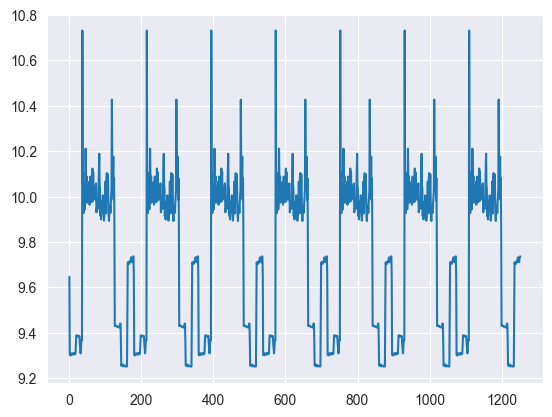

In [16]:
df_act.reset_index()['RESULTANT'].plot();

## Purely A-R Model

 We can treat the learned characteristics of the timeseries data observed to-date as informative about the structure of the unrealised future state of the same measure. 


In [37]:
## Set up a dictionary for the specification of our priors
## We set up the dictionary to specify size of the AR coefficients in
## case we want to vary the AR lags.
priors = {
    "coefs": {"mu": [10, 0.2], "sigma": [0.1, 0.1], "size": 2},
    "sigma": 8,
    "init": {"mu": 9, "sigma": 0.1, "size": 1},
}

## Initialise the model
with pm.Model() as AR:
    pass

## Define the time interval for fitting the data
t_data = list(range(len(df_act)))
## NOTE:  Add the time interval as a mutable coordinate to the model to allow for future predictions
AR.add_coord("obs_id", t_data, mutable=True)

In [38]:
with AR:
    ## Data containers to enable prediction
    t = pm.MutableData("t", t_data, dims="obs_id")
    y = pm.MutableData("y", df_act.RESULTANT , dims="obs_id")

    # The first coefficient will be the constant term but we need to set priors for each coefficient in the AR process
    coefs = pm.Normal("coefs", priors["coefs"]["mu"], priors["coefs"]["sigma"])
    
    # We need one init variable for each lag, hence size is variable too
    init = pm.Normal.dist(
        priors["init"]["mu"], priors["init"]["sigma"], size=priors["init"]["size"]
    )
    
    sigma = pm.HalfNormal("sigma", priors["sigma"])
    
    # Steps of the AR model minus the lags required
    ar1 = pm.AR(
        "ar",
        coefs,
        sigma=sigma,
        init_dist=init,
        constant=True,
        steps=t.shape[0] - (priors["coefs"]["size"] - 1),
        dims="obs_id",
    )

    # The Likelihood
    outcome = pm.Normal("likelihood", mu=ar1, sigma=sigma, observed=y, dims="obs_id")
    

In [39]:
with AR:
    ## Sampling
    idata_ar = pm.sample_prior_predictive()
    idata_ar.extend(pm.sample(2000, random_seed=100, target_accept=0.95))
    idata_ar.extend(pm.sample_posterior_predictive(idata_ar))

Sampling: [ar, coefs, likelihood, sigma]
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [coefs, sigma, ar]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 82 seconds.
Sampling: [likelihood]


In [23]:
idata_ar

Inference data with groups:
	> posterior
	> posterior_predictive
	> sample_stats
	> prior
	> prior_predictive
	> observed_data
	> constant_data

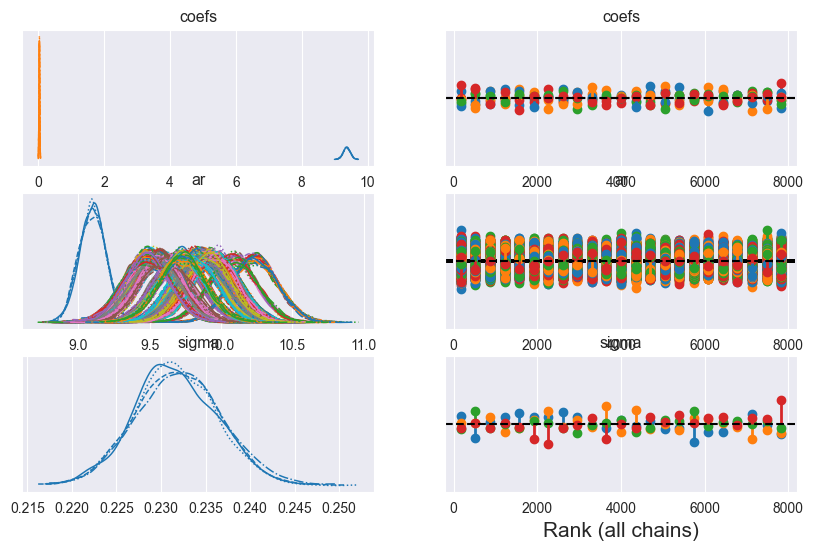

In [24]:
az.plot_trace(idata_ar, figsize=(10, 6), kind="rank_vlines");

In [25]:
az.summary(idata_ar, var_names=["~ar"])

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
coefs[0],9.368,0.104,9.160,9.557,0.001,0.001,10518.0,6009.0,1.0
coefs[1],0.037,0.011,0.016,0.057,0.000,0.000,10395.0,5847.0,1.0
sigma,0.232,0.005,0.223,0.240,0.000,0.000,3917.0,5720.0,1.0


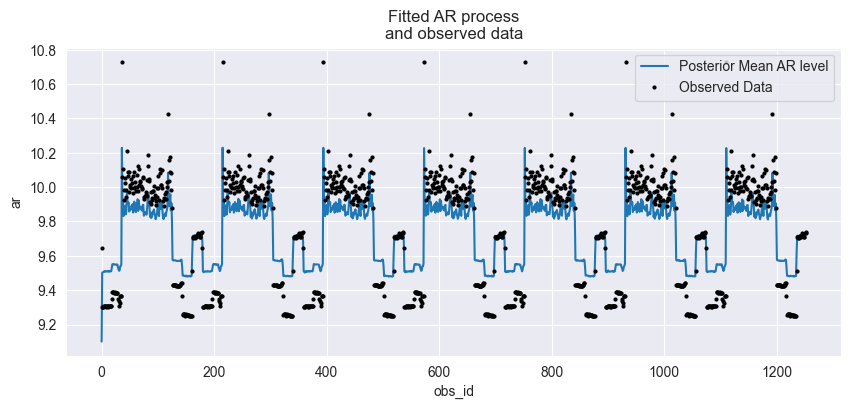

In [42]:
fig, ax = plt.subplots(figsize=(10, 4))
idata_ar.posterior.ar.mean(["chain", "draw"]).plot(ax=ax, label="Posterior Mean AR level")
ax.plot(df_act.RESULTANT.values, "o", color="black", markersize=2, label="Observed Data")
ax.legend()
ax.set_title("Fitted AR process\nand observed data");

### Predictions

 - Forecast from the  posterior given the observations so far

In [40]:
prediction_length = 1500
n = prediction_length - df_act.shape[0]
obs = list(range(prediction_length))

with AR:
    ## We need to have coords for the observations minus the lagged term to correctly centre the prediction step
    AR.add_coords({"obs_id_fut_1": range(df_act.RESULTANT.values.shape[0] - 1, prediction_length, 1)})
    AR.add_coords({"obs_id_fut": range(df_act.RESULTANT.values.shape[0], prediction_length, 1)})
    # condition on the learned values of the AR process
    # initialise the future AR process precisely at the last observed value in the AR process
    # using the special feature of the dirac delta distribution to be 0 everywhere else.
    ar1_fut = pm.AR(
        "ar1_fut",
        init_dist=pm.DiracDelta.dist(ar1[..., -1]),
        rho=coefs,
        sigma=sigma,
        constant=True,
        dims="obs_id_fut_1",
    )
    yhat_fut = pm.Normal("yhat_fut", mu=ar1_fut[1:], sigma=sigma, dims="obs_id_fut")
    # use the updated values and predict outcomes and probabilities:
    idata_preds = pm.sample_posterior_predictive(
        idata_ar, var_names=["likelihood", "yhat_fut"], predictions=True, random_seed=100
    )

Sampling: [ar1_fut, likelihood, yhat_fut]


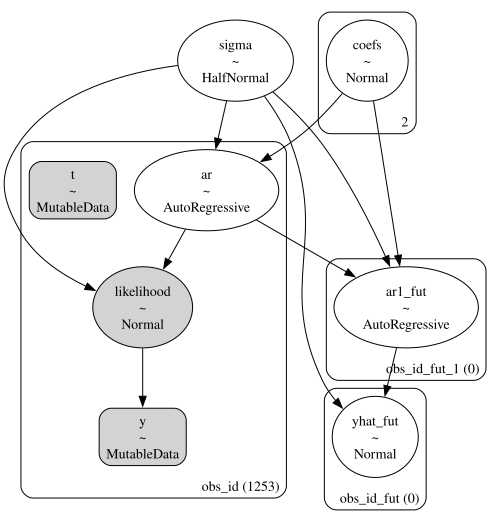

In [30]:
pm.model_to_graphviz(AR)

In [ ]:
def plot_fits(idata_ar, idata_preds):
    palette = "plasma"
    cmap = plt.get_cmap(palette)
    percs = np.linspace(51, 99, 100)
    colors = (percs - np.min(percs)) / (np.max(percs) - np.min(percs))
    mosaic = """AABB
                CCCC"""
    fig, axs = plt.subplot_mosaic(mosaic, sharex=False, figsize=(20, 10))
    axs = [axs[k] for k in axs.keys()]
    for i, p in enumerate(percs[::-1]):
        upper = np.percentile(
            az.extract_dataset(idata_ar, group="prior_predictive", num_samples=1000)["likelihood"],
            p,
            axis=1,
        )
        lower = np.percentile(
            az.extract_dataset(idata_ar, group="prior_predictive", num_samples=1000)["likelihood"],
            100 - p,
            axis=1,
        )
        color_val = colors[i]
        axs[0].fill_between(
            x=idata_ar["constant_data"]["t"],
            y1=upper.flatten(),
            y2=lower.flatten(),
            color=cmap(color_val),
            alpha=0.1,
        )

    axs[0].plot(
        az.extract_dataset(idata_ar, group="prior_predictive", num_samples=1000)["likelihood"].mean(
            axis=1
        ),
        color="cyan",
        label="Prior Predicted Mean Realisation",
    )

    axs[0].scatter(
        x=idata_ar["constant_data"]["t"],
        y=idata_ar["constant_data"]["y"],
        color="k",
        label="Observed Data points",
    )
    axs[0].set_title("Prior Predictive Fit", fontsize=20)
    axs[0].legend()

    for i, p in enumerate(percs[::-1]):
        upper = np.percentile(
            az.extract_dataset(idata_preds, group="predictions", num_samples=1000)["likelihood"],
            p,
            axis=1,
        )
        lower = np.percentile(
            az.extract_dataset(idata_preds, group="predictions", num_samples=1000)["likelihood"],
            100 - p,
            axis=1,
        )
        color_val = colors[i]
        axs[2].fill_between(
            x=idata_preds["predictions_constant_data"]["t"],
            y1=upper.flatten(),
            y2=lower.flatten(),
            color=cmap(color_val),
            alpha=0.1,
        )

        upper = np.percentile(
            az.extract_dataset(idata_preds, group="predictions", num_samples=1000)["yhat_fut"],
            p,
            axis=1,
        )
        lower = np.percentile(
            az.extract_dataset(idata_preds, group="predictions", num_samples=1000)["yhat_fut"],
            100 - p,
            axis=1,
        )
        color_val = colors[i]
        axs[2].fill_between(
            x=idata_preds["predictions"].coords["obs_id_fut"].data,
            y1=upper.flatten(),
            y2=lower.flatten(),
            color=cmap(color_val),
            alpha=0.1,
        )

    axs[2].plot(
        az.extract_dataset(idata_preds, group="predictions", num_samples=1000)["likelihood"].mean(
            axis=1
        ),
        color="cyan",
    )
    idata_preds.predictions.yhat_fut.mean(["chain", "draw"]).plot(
        ax=axs[2], color="cyan", label="Predicted Mean Realisation"
    )
    axs[2].scatter(
        x=idata_ar["constant_data"]["t"],
        y=idata_ar["constant_data"]["y"],
        color="k",
        label="Observed Data",
    )
    axs[2].set_title("Posterior Predictions Plotted", fontsize=20)
    axs[2].axvline(np.max(idata_ar["constant_data"]["t"]), color="black")
    axs[2].legend()
    axs[2].set_xlabel("Time in Days")
    axs[0].set_xlabel("Time in Days")
    az.plot_ppc(idata_ar, ax=axs[1])

/var/folders/j8/n524q16s54l6y_vxh70gb9lr0000gs/T/ipykernel_42548/3535912212.py:12: FutureWarning: extract_dataset has been deprecated, please use extract
  az.extract_dataset(idata_ar, group="prior_predictive", num_samples=1000)["likelihood"],
/var/folders/j8/n524q16s54l6y_vxh70gb9lr0000gs/T/ipykernel_42548/3535912212.py:17: FutureWarning: extract_dataset has been deprecated, please use extract
  az.extract_dataset(idata_ar, group="prior_predictive", num_samples=1000)["likelihood"],
/var/folders/j8/n524q16s54l6y_vxh70gb9lr0000gs/T/ipykernel_42548/3535912212.py:31: FutureWarning: extract_dataset has been deprecated, please use extract
  az.extract_dataset(idata_ar, group="prior_predictive", num_samples=1000)["likelihood"].mean(
/var/folders/j8/n524q16s54l6y_vxh70gb9lr0000gs/T/ipykernel_42548/3535912212.py:49: FutureWarning: extract_dataset has been deprecated, please use extract
  az.extract_dataset(idata_preds, group="predictions", num_samples=1000)["likelihood"],
/var/folders/j8/n524q

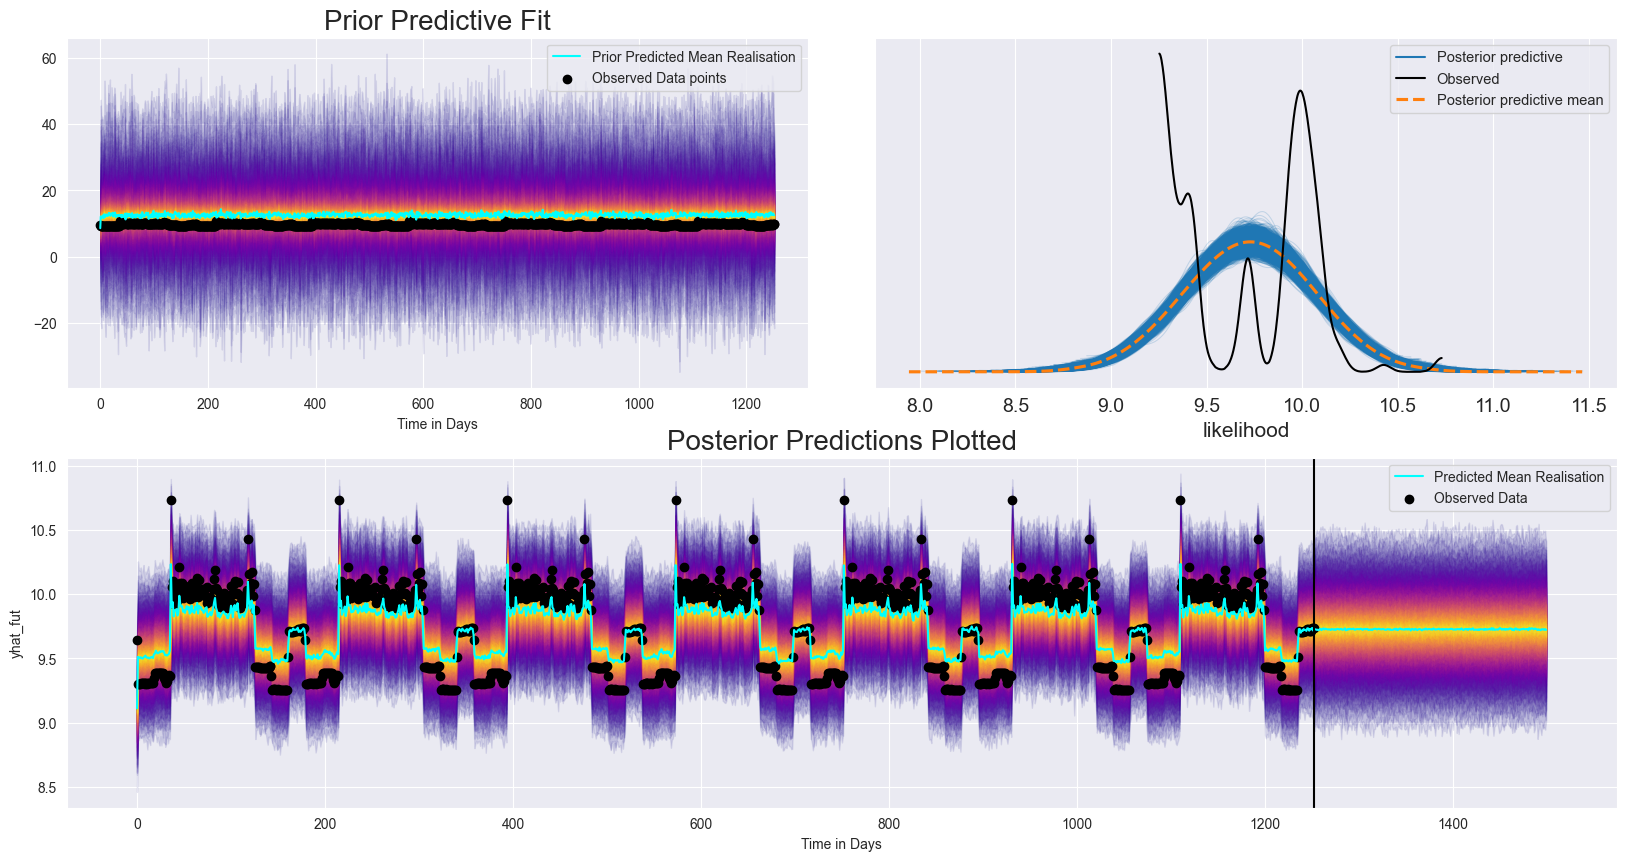

In [41]:


plot_fits(idata_ar, idata_preds)